In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from influxdb_client_3 import InfluxDBClient3

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (14, 5)
plt.rcParams["font.size"] = 11

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
HOST = "http://127.0.0.1:8182"
DATABASE = "fan_monitor"
TOKEN = "apiv3_Ynk9eheNcAjK2R9iBR7cvoLFAlQgT2YMAap8L9_SflJ-KepGFg85yDsvO1yMq35NbhlaOzZGKFj6UMHOGNs6bQ"

client = InfluxDBClient3(
    host=HOST,
    database=DATABASE,
    token=TOKEN if TOKEN else None
)

print("Connected to InfluxDB!")

Connected to InfluxDB!


In [5]:
query = """
SELECT
    time,
    current,
    freq,
    amp,
    dev
FROM fan_telemetry
WHERE time >= (
    SELECT MIN(time) + INTERVAL '10' HOUR
    FROM fan_telemetry
)
ORDER BY time ASC
"""

table = client.query(
    query=query,
    language="sql"
)

df = table.to_pandas()
df_clean = df[df["amp"] > 0].copy()

print("Data loaded successfully!")
print("Dataset shape:", df.shape)

Data loaded successfully!
Dataset shape: (81499, 5)


In [6]:
# Chỉ giữ hai tần số làm mốc vận hành ổn định ban đầu
stable_freqs = [19.5, 21.5]

df_stable = df[df["freq"].isin(stable_freqs)].copy()

print("Số bản ghi sau khi lọc freq:", len(df_stable))
display(df_stable["freq"].value_counts().sort_index().to_frame("count"))

Số bản ghi sau khi lọc freq: 54312


,count
freq,
19.5,44793
21.5,9519


In [7]:
df["time"] = pd.to_datetime(df["time"], errors="coerce")
df["freq"] = pd.to_numeric(df["freq"], errors="coerce")
df["amp"] = pd.to_numeric(df["amp"], errors="coerce")

df = (
    df.dropna(subset=["time"])
      .sort_values("time")
      .reset_index(drop=True)
)

# Chỉ giữ hai mức tần số
stable_freqs = [19.5, 21.5]

df_stable = df[df["freq"].isin(stable_freqs)].copy()

# Loại amp null và amp = 0
amp_df = df_stable.dropna(subset=["amp"]).copy()

zero_count = (amp_df["amp"] == 0).sum()

amp_df = amp_df[amp_df["amp"] > 0].copy()

print("Tổng số bản ghi:", len(df))
print("Số bản ghi thuộc freq 19.5 và 21.5 Hz:", len(df_stable))
print("Số bản ghi amp = 0 bị loại:", zero_count)
print("Số bản ghi amp hợp lệ:", len(amp_df))

print("Khoảng thời gian:")
print(amp_df["time"].min(), "->", amp_df["time"].max())

print("\nSố lượng mẫu theo freq:")
display(amp_df["freq"].value_counts().sort_index().to_frame("count"))

Tổng số bản ghi: 81499
Số bản ghi thuộc freq 19.5 và 21.5 Hz: 54312
Số bản ghi amp = 0 bị loại: 0
Số bản ghi amp hợp lệ: 54312
Khoảng thời gian:
2026-11-08 02:00:32.036961600 -> 2026-11-09 02:27:51.692285600

Số lượng mẫu theo freq:


,count
freq,
19.5,44793
21.5,9519


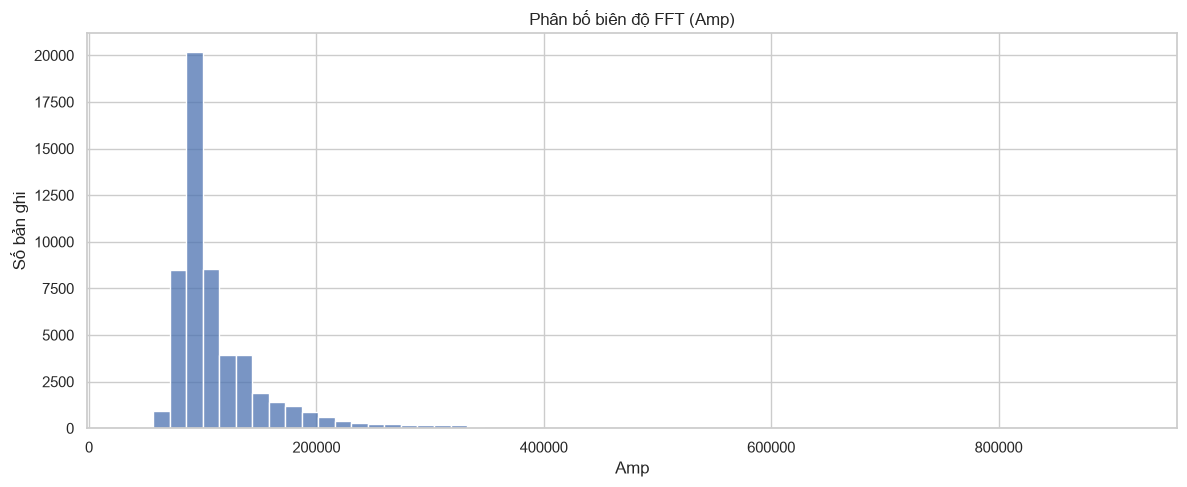

In [8]:
# Chỉ lấy hai nhóm tần số 19.5 Hz và 21.5 Hz
amp_df = df_clean[
    df_clean["freq"].isin([19.5, 21.5]) &
    (df_clean["amp"] > 0)
].copy()

plt.figure(figsize=(12, 5))

sns.histplot(
    data=amp_df,
    x="amp",
    bins=60
)

plt.title("Phân bố biên độ FFT (Amp)")
plt.xlabel("Amp")
plt.ylabel("Số bản ghi")

plt.tight_layout()
plt.show()

In [9]:
amp_stats = amp_df["amp"].agg(
    ["count", "mean", "median", "std", "min", "max"]
)

display(amp_stats.to_frame(name="amp"))

,amp
count,54312.000000
mean,116345.558103
median,97603.150000
std,64799.367506
min,42021.100000
max,913335.600000


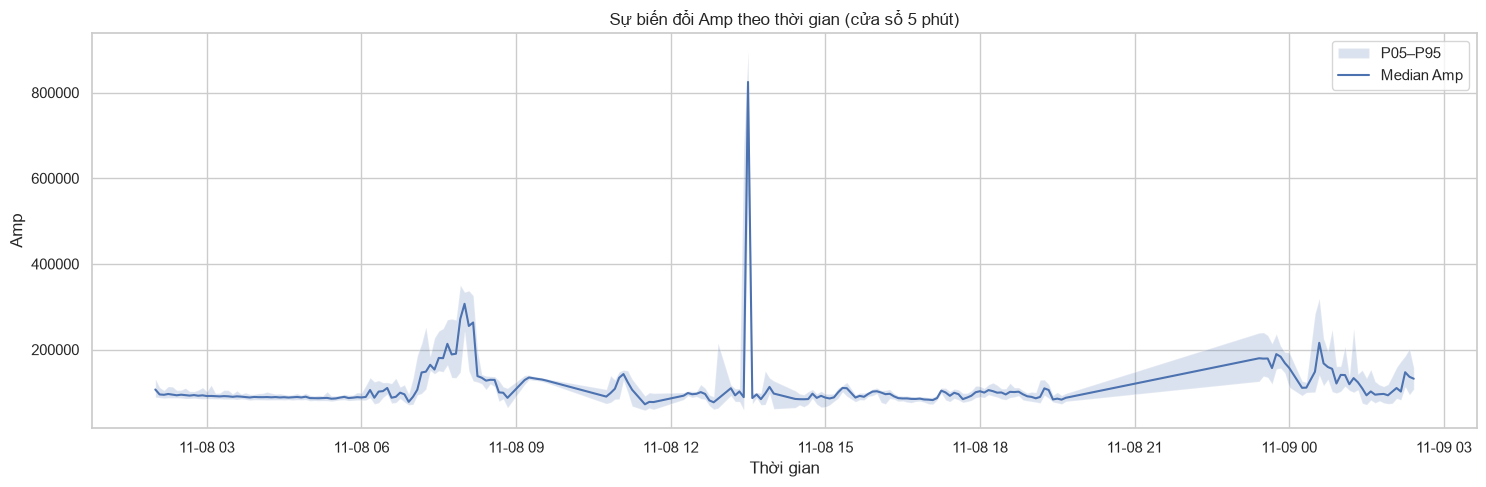

In [10]:
amp_time = amp_df.set_index("time").sort_index()

amp_window = amp_time["amp"].resample("5min").agg(
    count="count",
    median="median",
    p05=lambda x: x.quantile(0.05),
    p95=lambda x: x.quantile(0.95)
)

# Chỉ giữ cửa sổ có ít nhất 100 mẫu
amp_window = amp_window[amp_window["count"] >= 100]

plt.figure(figsize=(15, 5))

plt.fill_between(
    amp_window.index,
    amp_window["p05"],
    amp_window["p95"],
    alpha=0.2,
    label="P05–P95"
)

plt.plot(
    amp_window.index,
    amp_window["median"],
    linewidth=1.5,
    label="Median Amp"
)

plt.title("Sự biến đổi Amp theo thời gian (cửa sổ 5 phút)")
plt.xlabel("Thời gian")
plt.ylabel("Amp")
plt.legend()
plt.tight_layout()
plt.show()